# CycleGAN: face photos ↔ sketches

## 128 × 128 / six-residual-block configuration

**Restart the Colab runtime, enable the T4 GPU, and run cells from top to bottom.** Changing a constant alone does not rebuild already-created models, datasets, or traced training functions. This version replaces the previous 256 × 256 / nine-block trial. Old outputs have been cleared.

This notebook covers setup, preprocessing, network construction, losses, checkpoint setup, and a short benchmark. **It is not yet the complete assignment**: the epoch loop, validation/sample logging, final evaluation, automatic input classifier, and Flask UI will be added in subsequent steps.

Checkpoints restore model/optimizer progress, not exact replay-buffer or random-generator state. Keep test data for final evaluation.

References: [CycleGAN paper](https://arxiv.org/abs/1703.10593), [authors’ implementation](https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix), [dataset](https://www.kaggle.com/datasets/almightyj/person-face-sketches).

## 0. Install dependencies and check the GPU


In [7]:
%pip -q install pillow matplotlib

import tensorflow as tf

print("TensorFlow version:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus)
if not gpus:
    raise RuntimeError("Enable a GPU runtime before continuing.")

Note: you may need to restart the kernel to use updated packages.
TensorFlow version: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 1. Add the dataset

In [8]:
from pathlib import Path

dataset_path = Path("/kaggle/input/datasets/almightyj/person-face-sketches")
assert (dataset_path / "train" / "photos").exists(), "Dataset path is wrong or dataset not added"

print("Dataset location:", dataset_path)

Dataset location: /kaggle/input/datasets/almightyj/person-face-sketches


## 2. Inspect the dataset splits

Count images in each folder. Preserve the provided train/validation/test splits. All 20,655 training images per domain are retained; no sample reduction is applied.

In [9]:
from collections import defaultdict

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}
image_folders = defaultdict(list)

for file in dataset_path.rglob("*"):
    if file.is_file() and file.suffix.lower() in image_extensions:
        image_folders[file.parent].append(file.name)

print("Total images:", sum(len(files) for files in image_folders.values()))

for folder, filenames in sorted(image_folders.items()):
    print(f"\nFolder: {folder.relative_to(dataset_path)}")
    print(f"Images: {len(filenames)}")
    print("Example filenames:", sorted(filenames)[:5])

Total images: 44668

Folder: test/photos
Images: 679
Example filenames: ['10132.jpg', '1020.jpg', '10223.jpg', '10323.jpg', '10361.jpg']

Folder: test/sketches
Images: 679
Example filenames: ['10132.jpg', '1020.jpg', '10223.jpg', '10323.jpg', '10361.jpg']

Folder: train/photos
Images: 20655
Example filenames: ['0.jpg', '1.jpg', '10.jpg', '100.jpg', '10001.jpg']

Folder: train/sketches
Images: 20655
Example filenames: ['0.jpg', '1.jpg', '10.jpg', '100.jpg', '10001.jpg']

Folder: val/photos
Images: 1000
Example filenames: ['10031.jpg', '10078.jpg', '10111.jpg', '1018.jpg', '10183.jpg']

Folder: val/sketches
Images: 1000
Example filenames: ['10031.jpg', '10078.jpg', '10111.jpg', '1018.jpg', '10183.jpg']


## 3. View photo and sketch examples

Inspect matched filenames for visual understanding. Photos are RGB and sketches are grayscale. Matching pairs are useful for inspection, but training will shuffle the two domains independently.

photos/14851.jpg: size=(512, 512), mode=RGB
sketches/14851.jpg: size=(512, 512), mode=L
photos/11077.jpg: size=(512, 512), mode=RGB
sketches/11077.jpg: size=(512, 512), mode=L
photos/219.jpg: size=(512, 512), mode=RGB
sketches/219.jpg: size=(512, 512), mode=L
photos/20601.jpg: size=(512, 512), mode=RGB
sketches/20601.jpg: size=(512, 512), mode=L


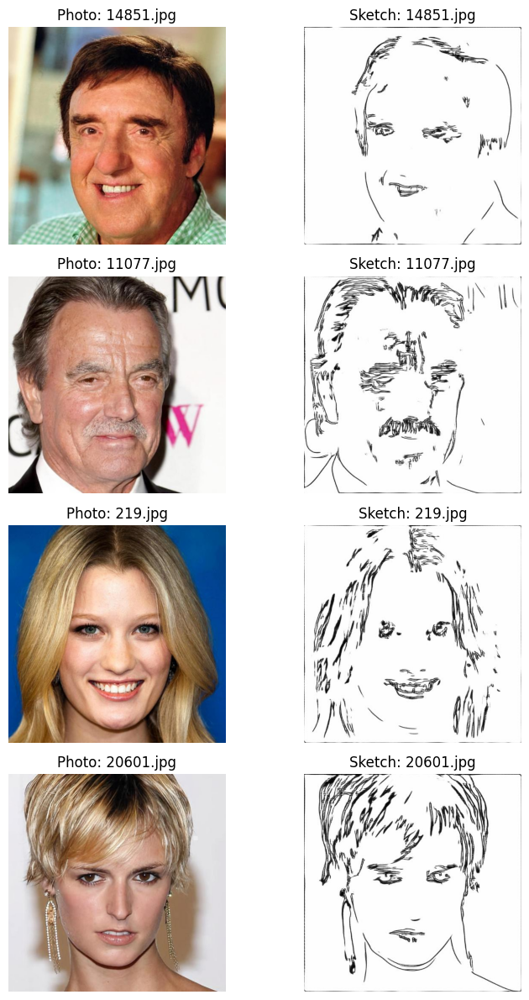

In [10]:
from PIL import Image
import matplotlib.pyplot as plt
import random

# Paths to the existing dataset splits.
train_photo_dir = dataset_path / "train" / "photos"
train_sketch_dir = dataset_path / "train" / "sketches"

val_photo_dir = dataset_path / "val" / "photos"
val_sketch_dir = dataset_path / "val" / "sketches"

test_photo_dir = dataset_path / "test" / "photos"
test_sketch_dir = dataset_path / "test" / "sketches"


def show_sample_pairs(photo_dir, sketch_dir, count=4):
    """Display images with matching filenames and print their properties."""
    photo_names = {
        p.name for p in photo_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    }
    sketch_names = {
        p.name for p in sketch_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    }

    matching_names = sorted(photo_names & sketch_names)
    if not matching_names:
        raise ValueError("No matching photo/sketch filenames found.")

    selected = random.Random(42).sample(
        matching_names, min(count, len(matching_names))
    )

    fig, axes = plt.subplots(
        len(selected), 2,
        figsize=(8, 3 * len(selected)),
        squeeze=False
    )

    for row, filename in enumerate(selected):
        for col, folder in enumerate([photo_dir, sketch_dir]):
            with Image.open(folder / filename) as img:
                print(
                    f"{folder.name}/{filename}: "
                    f"size={img.size}, mode={img.mode}"
                )

                axes[row, col].imshow(img.convert("RGB"))
                axes[row, col].set_title(
                    f"{'Photo' if col == 0 else 'Sketch'}: {filename}"
                )
                axes[row, col].axis("off")

    plt.tight_layout()
    plt.show()


show_sample_pairs(train_photo_dir, train_sketch_dir)

## 4. Prepare the TensorFlow input pipeline

Resize images to **128 × 128**, decode both domains as three channels, and normalize pixels with `pixel / 127.5 - 1`. Grayscale sketches are repeated across RGB channels. Training uses random horizontal flips and independently shuffled paths. Validation/test inputs are not augmented. Batch size is 1, and files are loaded on demand.

In [11]:
import tensorflow as tf

IMAGE_SIZE = 128
NUM_RESIDUAL_BLOCKS = 6
BATCH_SIZE = 1
AUTOTUNE = tf.data.AUTOTUNE

tf.keras.utils.set_random_seed(42)


def get_image_paths(folder):
    """Return sorted image paths without loading images into memory."""
    paths = sorted(
        str(path)
        for path in folder.iterdir()
        if path.is_file() and path.suffix.lower() in image_extensions
    )

    if not paths:
        raise ValueError(f"No images found in {folder}")

    return paths


def load_image(path):
    """Decode an image as RGB, resize it, and normalize to [-1, 1]."""
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image, [IMAGE_SIZE, IMAGE_SIZE], antialias=True
    )
    image = tf.cast(image, tf.float32)
    image = (image / 127.5) - 1.0

    return image


def augment_image(image):
    """Randomly flip a training image horizontally."""
    return tf.image.random_flip_left_right(image)


def create_dataset(paths, training=False, seed=42):
    """Load images on demand and prepare batches for the model."""
    dataset = tf.data.Dataset.from_tensor_slices(paths)

    if training:
        # Shuffle file paths before decoding to keep memory usage low.
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=seed,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image, num_parallel_calls=AUTOTUNE
    )

    if training:
        dataset = dataset.map(
            augment_image, num_parallel_calls=AUTOTUNE
        )

    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


# Keep the dataset's existing splits.
train_photo_paths = get_image_paths(train_photo_dir)
train_sketch_paths = get_image_paths(train_sketch_dir)

val_photo_paths = get_image_paths(val_photo_dir)
val_sketch_paths = get_image_paths(val_sketch_dir)

test_photo_paths = get_image_paths(test_photo_dir)
test_sketch_paths = get_image_paths(test_sketch_dir)

# Different shuffle seeds make training pairs independent.
train_photos = create_dataset(train_photo_paths, training=True, seed=42)
train_sketches = create_dataset(train_sketch_paths, training=True, seed=123)

train_dataset = tf.data.Dataset.zip((train_photos, train_sketches))

# No random augmentation or shuffling for validation/testing.
val_photos = create_dataset(val_photo_paths)
val_sketches = create_dataset(val_sketch_paths)

test_photos = create_dataset(test_photo_paths)
test_sketches = create_dataset(test_sketch_paths)

print("Training batches per epoch:", len(train_dataset))

I0000 00:00:1792155633.766398    1118 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792155633.768638    1118 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Training batches per epoch: 20655


## 5. Check a training batch

Expect both shapes to be **(1, 128, 128, 3)** and values within [-1, 1]; each image need not reach both extremes. Display converts values back to [0, 1]. The photo and sketch usually belong to different people.

Photo batch shape: (1, 128, 128, 3)
Sketch batch shape: (1, 128, 128, 3)
Photo pixel range: -0.9999693632125854 to 0.597771167755127
Sketch pixel range: -0.8971890211105347 to 0.9931832551956177


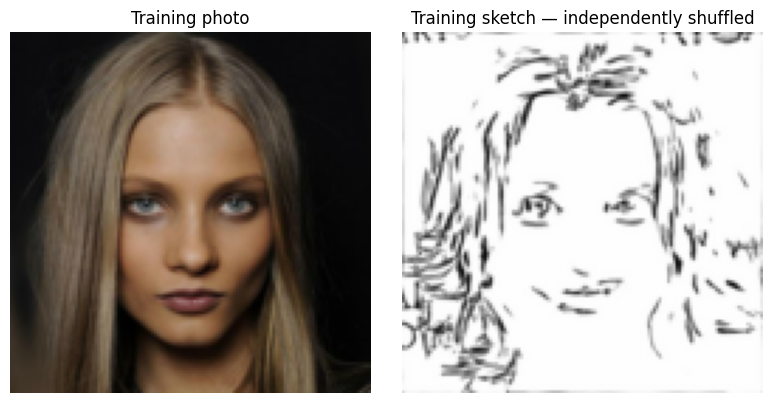

In [12]:
import matplotlib.pyplot as plt

photo_batch, sketch_batch = next(iter(train_dataset))

print("Photo batch shape:", photo_batch.shape)
print("Sketch batch shape:", sketch_batch.shape)

print(
    "Photo pixel range:",
    float(tf.reduce_min(photo_batch)),
    "to",
    float(tf.reduce_max(photo_batch))
)

print(
    "Sketch pixel range:",
    float(tf.reduce_min(sketch_batch)),
    "to",
    float(tf.reduce_max(sketch_batch))
)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# Convert [-1, 1] back to [0, 1] for display.
axes[0].imshow(tf.clip_by_value((photo_batch[0] + 1) / 2, 0, 1))
axes[0].set_title("Training photo")
axes[0].axis("off")

axes[1].imshow(tf.clip_by_value((sketch_batch[0] + 1) / 2, 0, 1))
axes[1].set_title("Training sketch — independently shuffled")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 6. Define normalization and padding layers

Instance normalization normalizes each channel within each image, then applies learned scale and bias. Reflection padding mirrors borders before convolutions. Both custom layers are registered for Keras serialization; run these definitions before loading exported models.

In [13]:
from tensorflow.keras import layers, Model


@tf.keras.utils.register_keras_serializable(package="CycleGAN")
class InstanceNormalization(layers.Layer):
    """Normalize each channel independently within each image."""

    def __init__(self, epsilon=1e-5, **kwargs):
        super().__init__(**kwargs)
        self.epsilon = epsilon

    def build(self, input_shape):
        channels = int(input_shape[-1])

        self.gamma = self.add_weight(
            name="gamma",
            shape=(channels,),
            initializer="ones",
            trainable=True
        )
        self.beta = self.add_weight(
            name="beta",
            shape=(channels,),
            initializer="zeros",
            trainable=True
        )
        super().build(input_shape)

    def call(self, inputs):
        mean, variance = tf.nn.moments(
            inputs, axes=[1, 2], keepdims=True
        )
        normalized = (inputs - mean) * tf.math.rsqrt(
            variance + self.epsilon
        )
        return self.gamma * normalized + self.beta

    def get_config(self):
        config = super().get_config()
        config.update({"epsilon": self.epsilon})
        return config


@tf.keras.utils.register_keras_serializable(package="CycleGAN")
class ReflectionPadding2D(layers.Layer):
    """Pad spatial borders using reflected pixel values."""

    def __init__(self, padding=1, **kwargs):
        super().__init__(**kwargs)
        self.padding = padding

    def call(self, inputs):
        p = self.padding
        return tf.pad(
            inputs,
            [[0, 0], [p, p], [p, p], [0, 0]],
            mode="REFLECT"
        )

    def compute_output_shape(self, input_shape):
        batch, height, width, channels = input_shape
        p = self.padding

        return (
            batch,
            height + 2 * p if height is not None else None,
            width + 2 * p if width is not None else None,
            channels
        )

    def get_config(self):
        config = super().get_config()
        config.update({"padding": self.padding})
        return config

## 7. Build the two generators

`G` converts photos to sketches; `F` converts sketches to photos. Their architectures match, but their weights are independent. Each has **six residual blocks**. A residual block adds its learned change to its input.

| Stage | Shape (without batch) |
|---|---|
| Input | 128 × 128 × 3 |
| Initial convolution | 128 × 128 × 64 |
| Downsample | 64 × 64 × 128 |
| Downsample / six residual blocks | 32 × 32 × 256 |
| Upsample | 64 × 64 × 128 |
| Upsample | 128 × 128 × 64 |
| Tanh output | 128 × 128 × 3 |

Hidden activations use ReLU. Tanh limits output pixels to [-1, 1].

In [14]:
def weight_initializer():
    """Create a fresh initializer for each convolution."""
    return tf.keras.initializers.RandomNormal(mean=0.0, stddev=0.02)


def residual_block(x, filters=256):
    """Learn a residual transformation while preserving spatial size."""
    shortcut = x

    x = ReflectionPadding2D(1)(x)
    x = layers.Conv2D(
        filters, kernel_size=3, padding="valid",
        kernel_initializer=weight_initializer()
    )(x)
    x = InstanceNormalization()(x)
    x = layers.ReLU()(x)

    x = ReflectionPadding2D(1)(x)
    x = layers.Conv2D(
        filters, kernel_size=3, padding="valid",
        kernel_initializer=weight_initializer()
    )(x)
    x = InstanceNormalization()(x)

    return layers.Add()([shortcut, x])


def build_generator(name, num_residual_blocks=6):
    """Build a ResNet image-to-image generator."""
    inputs = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))

    # Initial feature extraction.
    x = ReflectionPadding2D(3)(inputs)
    x = layers.Conv2D(
        64, kernel_size=7, padding="valid",
        kernel_initializer=weight_initializer()
    )(x)
    x = InstanceNormalization()(x)
    x = layers.ReLU()(x)

    # Reduce spatial size and increase feature channels.
    for filters in [128, 256]:
        x = layers.Conv2D(
            filters, kernel_size=3, strides=2, padding="same",
            kernel_initializer=weight_initializer()
        )(x)
        x = InstanceNormalization()(x)
        x = layers.ReLU()(x)

    # Transform the compressed features.
    for _ in range(num_residual_blocks):
        x = residual_block(x, filters=256)

    # Restore the original spatial resolution.
    for filters in [128, 64]:
        x = layers.Conv2DTranspose(
            filters, kernel_size=3, strides=2, padding="same",
            kernel_initializer=weight_initializer()
        )(x)
        x = InstanceNormalization()(x)
        x = layers.ReLU()(x)

    # Produce RGB pixels in [-1, 1].
    x = ReflectionPadding2D(3)(x)
    outputs = layers.Conv2D(
        3, kernel_size=7, padding="valid",
        activation="tanh",
        kernel_initializer=weight_initializer()
    )(x)

    return Model(inputs, outputs, name=name)


G = build_generator("photo_to_sketch", NUM_RESIDUAL_BLOCKS)
F = build_generator("sketch_to_photo", NUM_RESIDUAL_BLOCKS)

print("G parameters:", f"{G.count_params():,}")
print("F parameters:", f"{F.count_params():,}")

G parameters: 7,845,123
F parameters: 7,845,123


## 8. Check generator outputs

Run forward passes without updating weights. Both outputs should have shape **(1, 128, 128, 3)** and finite values. Untrained outputs are not meaningful translations.

In [15]:
# Forward passes only: no training happens here.
generated_sketch = G(photo_batch, training=False)
generated_photo = F(sketch_batch, training=False)

print("Photo → Sketch:", generated_sketch.shape)
print("Sketch → Photo:", generated_photo.shape)

tf.debugging.assert_all_finite(
    generated_sketch, "Generator G produced invalid values."
)
tf.debugging.assert_all_finite(
    generated_photo, "Generator F produced invalid values."
)

print("Both generators passed the forward-pass check.")

Photo → Sketch: (1, 128, 128, 3)
Sketch → Photo: (1, 128, 128, 3)
Both generators passed the forward-pass check.


## 9. Build the two PatchGAN discriminators

`D_photo` judges photos; `D_sketch` judges sketches. The 70 × 70 PatchGAN architecture now returns a **14 × 14 score grid** for a 128 × 128 input. Each score evaluates an overlapping local region. LeakyReLU is used internally; there is no output sigmoid because we use least-squares adversarial loss.

In [16]:
def discriminator_block(x, filters, stride, normalize=True):
    """Apply a convolution, optional normalization, and LeakyReLU."""
    x = layers.ZeroPadding2D(padding=1)(x)

    x = layers.Conv2D(
        filters,
        kernel_size=4,
        strides=stride,
        padding="valid",
        kernel_initializer=weight_initializer()
    )(x)

    if normalize:
        x = InstanceNormalization()(x)

    return layers.LeakyReLU(negative_slope=0.2)(x)


def build_discriminator(name):
    """Build a 70x70 PatchGAN discriminator for RGB images."""
    inputs = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))

    # Spatial sizes: 128 → 64 → 32 → 16 → 15.
    x = discriminator_block(
        inputs, filters=64, stride=2, normalize=False
    )
    x = discriminator_block(x, filters=128, stride=2)
    x = discriminator_block(x, filters=256, stride=2)
    x = discriminator_block(x, filters=512, stride=1)

    # Produce a 14x14 grid of unrestricted patch scores.
    x = layers.ZeroPadding2D(padding=1)(x)
    outputs = layers.Conv2D(
        1,
        kernel_size=4,
        strides=1,
        padding="valid",
        kernel_initializer=weight_initializer()
    )(x)

    return Model(inputs, outputs, name=name)


D_photo = build_discriminator("photo_discriminator")
D_sketch = build_discriminator("sketch_discriminator")

print("D_photo parameters:", f"{D_photo.count_params():,}")
print("D_sketch parameters:", f"{D_sketch.count_params():,}")

D_photo parameters: 2,766,529
D_sketch parameters: 2,766,529


## 10. Check discriminator outputs

All four outputs should be **(1, 14, 14, 1)**. Raw scores may be outside [0, 1]. Targets of 1 and 0 are used by the loss; these scores are not probabilities.

In [17]:
# Each discriminator processes images from its own target domain.
photo_real_scores = D_photo(photo_batch, training=False)
photo_fake_scores = D_photo(generated_photo, training=False)

sketch_real_scores = D_sketch(sketch_batch, training=False)
sketch_fake_scores = D_sketch(generated_sketch, training=False)

score_batches = {
    "Real photo": photo_real_scores,
    "Generated photo": photo_fake_scores,
    "Real sketch": sketch_real_scores,
    "Generated sketch": sketch_fake_scores
}

for label, scores in score_batches.items():
    print(f"{label}: {scores.shape}")
    tf.debugging.assert_all_finite(
        scores, f"Invalid discriminator scores for {label}"
    )

print("Both discriminators passed the forward-pass check.")

Real photo: (1, 14, 14, 1)
Generated photo: (1, 14, 14, 1)
Real sketch: (1, 14, 14, 1)
Generated sketch: (1, 14, 14, 1)
Both discriminators passed the forward-pass check.


## 11. Define the CycleGAN losses

Adversarial squared error encourages realistic translations. Cycle L1 loss compares `F(G(photo))` with the photo and `G(F(sketch))` with the sketch, weighted by 10. Identity L1 loss compares `G(sketch)` with the sketch and `F(photo)` with the photo, weighted by 5. Both generator totals include both cycle losses. Discriminator loss averages real-target-1 and fake-target-0 squared errors.

In [18]:
LAMBDA_CYCLE = 10.0
LAMBDA_IDENTITY = 5.0


def generator_adversarial_loss(fake_scores):
    """Encourage generated images to receive real-image scores of 1."""
    return tf.reduce_mean(tf.square(fake_scores - 1.0))


def discriminator_loss(real_scores, fake_scores):
    """Encourage scores of 1 for real images and 0 for generated images."""
    real_loss = tf.reduce_mean(tf.square(real_scores - 1.0))
    fake_loss = tf.reduce_mean(tf.square(fake_scores))

    return 0.5 * (real_loss + fake_loss)


def cycle_consistency_loss(original, reconstructed):
    """Penalize changes after an image passes through both generators."""
    return LAMBDA_CYCLE * tf.reduce_mean(
        tf.abs(original - reconstructed)
    )


def identity_loss(original, same_domain_output):
    """Penalize changes to images already in the output domain."""
    return LAMBDA_IDENTITY * tf.reduce_mean(
        tf.abs(original - same_domain_output)
    )

## 12. Create separate optimizers

Each network gets its own Adam optimizer: learning rate 0.0002, beta_1 0.5, beta_2 0.999. These are starting settings; the full training schedule will be added after benchmarking. Do not recreate optimizers during a continuing run unless you immediately restore their state.

In [20]:
LEARNING_RATE = 2e-4


def create_optimizer():
    """Create an Adam optimizer for one network."""
    return tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE,
        beta_1=0.5,
        beta_2=0.999
    )


G_optimizer = create_optimizer()
F_optimizer = create_optimizer()

D_photo_optimizer = create_optimizer()
D_sketch_optimizer = create_optimizer()

print("Loss functions and four optimizers are ready.")

Loss functions and four optimizers are ready.


## 13. Check the loss formulas

Synthetic scores verify the formulas independently of model quality. Expected values, in order: **0, 1, 0, 0, 0**.

In [21]:
real_scores = tf.ones_like(photo_real_scores)
fake_scores = tf.zeros_like(photo_fake_scores)

print(
    "Perfect discriminator loss:",
    float(discriminator_loss(real_scores, fake_scores))
)

print(
    "Generator loss when fake scores are 0:",
    float(generator_adversarial_loss(fake_scores))
)

print(
    "Generator loss when fake scores are 1:",
    float(generator_adversarial_loss(real_scores))
)

print(
    "Cycle loss for identical images:",
    float(cycle_consistency_loss(photo_batch, photo_batch))
)

print(
    "Identity loss for identical images:",
    float(identity_loss(sketch_batch, sketch_batch))
)

Perfect discriminator loss: 0.0
Generator loss when fake scores are 0: 1.0
Generator loss when fake scores are 1: 0.0
Cycle loss for identical images: 0.0
Identity loss for identical images: 0.0


## 14. Connect Drive and isolate this experiment

Use a separate **128px_resnet6** run directory. This avoids restoring incompatible weights from the previous 256px/9-block model. Existing old checkpoints remain untouched. Colab will ask you to authorize Drive access.

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/CycleGAN_Assignment")
RUN_DIR = PROJECT_DIR / f"{IMAGE_SIZE}px_resnet{NUM_RESIDUAL_BLOCKS}"
CHECKPOINT_DIR = RUN_DIR / "checkpoints"
SAMPLE_DIR = RUN_DIR / "samples"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
SAMPLE_DIR.mkdir(parents=True, exist_ok=True)

print("Run folder:", RUN_DIR)

### KAGGLE CHANGE

In [23]:
import os, shutil
from pathlib import Path

PROJECT_DIR = Path("/kaggle/working/CycleGAN_Assignment")   # writable output location
RUN_DIR = PROJECT_DIR / f"{IMAGE_SIZE}px_resnet{NUM_RESIDUAL_BLOCKS}"
CHECKPOINT_DIR = RUN_DIR / "checkpoints"
SAMPLE_DIR = RUN_DIR / "samples"

# Find the uploaded run folder (the parent of a "checkpoints" directory) in /kaggle/input.
src = None
for root, dirs, _ in os.walk("/kaggle/input"):
    if "person-face-sketches" in root:
        dirs[:] = []          # don't walk the image dataset
        continue
    if "checkpoints" in dirs:
        src = Path(root)
        break

if src is not None and not any(CHECKPOINT_DIR.glob("ckpt-*.index")):
    shutil.copytree(src, RUN_DIR, dirs_exist_ok=True)
    print("Copied saved run from:", src)
elif src is None:
    print("No uploaded checkpoints found. Starting from scratch.")

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
SAMPLE_DIR.mkdir(parents=True, exist_ok=True)

print("Run folder:", RUN_DIR)
print("Checkpoint files:", sorted(p.name for p in CHECKPOINT_DIR.glob("ckpt-*.index")))

Run folder: /kaggle/working/CycleGAN_Assignment/128px_resnet6
Checkpoint files: ['ckpt-252.index', 'ckpt-253.index', 'ckpt-254.index']


## 15. Prepare checkpoint state

Track all four networks, their optimizer states, and completed epochs. Build optimizer variables before restoration. Keep the latest three checkpoints; the future epoch loop will save after every epoch.

In [24]:
# Create optimizer state variables before restoring saved training state.
for optimizer, model in [
    (G_optimizer, G),
    (F_optimizer, F),
    (D_photo_optimizer, D_photo),
    (D_sketch_optimizer, D_sketch)
]:
    optimizer.build(model.trainable_variables)

completed_epochs = tf.Variable(
    0, dtype=tf.int64, trainable=False, name="completed_epochs"
)

checkpoint = tf.train.Checkpoint(
    completed_epochs=completed_epochs,
    G=G,
    F=F,
    D_photo=D_photo,
    D_sketch=D_sketch,
    G_optimizer=G_optimizer,
    F_optimizer=F_optimizer,
    D_photo_optimizer=D_photo_optimizer,
    D_sketch_optimizer=D_sketch_optimizer
)

checkpoint_manager = tf.train.CheckpointManager(
    checkpoint,
    directory=str(CHECKPOINT_DIR),
    max_to_keep=3
)

print("Checkpoint manager is ready.")

Checkpoint manager is ready.


### Restore saved training progress

If this experiment already has a checkpoint, restore it before any updates. A first run starts from scratch. Do not point this folder at the old nine-block checkpoint.

In [18]:
RESTORED_CHECKPOINT = checkpoint_manager.latest_checkpoint is not None

if RESTORED_CHECKPOINT:
    restore_status = checkpoint.restore(checkpoint_manager.latest_checkpoint)
    restore_status.assert_existing_objects_matched()
    print("Restored:", checkpoint_manager.latest_checkpoint)
    print("Completed epochs:", int(completed_epochs.numpy()))
    print("Next epoch:", int(completed_epochs.numpy()) + 1)
else:
    print("No checkpoint for this configuration. Starting from epoch 1.")

Restored: /kaggle/working/CycleGAN_Assignment/128px_resnet6/checkpoints/ckpt-254
Completed epochs: 11
Next epoch: 12


**KAGGLE UPDATE**

In [25]:
# --- NEW: find the latest checkpoint, with a fallback if the index file has stale paths ---
latest = checkpoint_manager.latest_checkpoint
if latest is None:
    indexes = sorted(CHECKPOINT_DIR.glob("ckpt-*.index"),
                     key=lambda p: int(p.stem.split("-")[1]))
    if indexes:
        latest = str(indexes[-1].with_suffix(""))

# --- CHANGED: uses `latest` instead of checkpoint_manager.latest_checkpoint ---
RESTORED_CHECKPOINT = latest is not None

if RESTORED_CHECKPOINT:
    restore_status = checkpoint.restore(latest)                 # CHANGED
    restore_status.assert_existing_objects_matched()
    print("Restored:", latest)                                  # CHANGED
    print("Completed epochs:", int(completed_epochs.numpy()))
    print("Next epoch:", int(completed_epochs.numpy()) + 1)
else:
    print("No checkpoint for this configuration. Starting from epoch 1.")

Restored: /kaggle/working/CycleGAN_Assignment/128px_resnet6/checkpoints/ckpt-254
Completed epochs: 11
Next epoch: 12


## 16. Define checkpoint saving

This function saves a completed epoch; defining it does not save anything. Call it only after an entire epoch finishes. Mid-epoch recovery and the epoch loop are not implemented in this version.

In [26]:
def save_training_checkpoint(epoch_number):
    """Save all networks and optimizers after a completed epoch."""
    completed_epochs.assign(epoch_number)

    saved_path = checkpoint_manager.save(
        checkpoint_number=epoch_number
    )

    print(f"Saved epoch {epoch_number}: {saved_path}")

## 17. Create generated-image history buffers

Each domain keeps up to 50 generated images in CPU memory. Discriminators see a mixture of current and older outputs, which can stabilize training. Buffers are not included in these checkpoints and refill after restarting.

In [27]:
import numpy as np
import random


class ImagePool:
    """Store previous generated images for discriminator training."""

    def __init__(self, pool_size=50, seed=42):
        self.pool_size = pool_size
        self.images = []
        self.rng = random.Random(seed)

    def query(self, batch):
        """Return a mixture of current images and buffered images."""
        batch_numpy = tf.stop_gradient(batch).numpy()
        selected_images = []

        for image in batch_numpy:
            image = image.copy()

            if self.pool_size == 0:
                selected_images.append(image)

            elif len(self.images) < self.pool_size:
                self.images.append(image)
                selected_images.append(image)

            elif self.rng.random() > 0.5:
                index = self.rng.randrange(self.pool_size)

                old_image = self.images[index].copy()
                self.images[index] = image
                selected_images.append(old_image)

            else:
                selected_images.append(image)

        return tf.convert_to_tensor(
            np.stack(selected_images), dtype=batch.dtype
        )


photo_pool = ImagePool(pool_size=50, seed=42)
sketch_pool = ImagePool(pool_size=50, seed=123)

print("Image history buffers are ready.")

Image history buffers are ready.


## 18. Implement the generator update

Compute translations, both reverse cycles, and identity outputs. Differentiate each generator total and update only its weights. Discriminators provide differentiable scores but are not updated here. TensorFlow compiles this function on its first call.

In [28]:
@tf.function
def train_generators(real_photo, real_sketch):
    """Update both generators using adversarial, cycle, and identity losses."""
    with tf.GradientTape(persistent=True) as tape:
        # Translate into the opposite domain.
        fake_sketch = G(real_photo, training=True)
        fake_photo = F(real_sketch, training=True)

        # Translate back to reconstruct the original inputs.
        cycled_photo = F(fake_sketch, training=True)
        cycled_sketch = G(fake_photo, training=True)

        # Images already belonging to each generator's output domain.
        same_sketch = G(real_sketch, training=True)
        same_photo = F(real_photo, training=True)

        # Discriminators judge generated images.
        # Their weights are not updated in this function.
        fake_sketch_scores = D_sketch(fake_sketch, training=False)
        fake_photo_scores = D_photo(fake_photo, training=False)

        G_adversarial = generator_adversarial_loss(fake_sketch_scores)
        F_adversarial = generator_adversarial_loss(fake_photo_scores)

        photo_cycle = cycle_consistency_loss(real_photo, cycled_photo)
        sketch_cycle = cycle_consistency_loss(real_sketch, cycled_sketch)
        total_cycle = photo_cycle + sketch_cycle

        G_identity = identity_loss(real_sketch, same_sketch)
        F_identity = identity_loss(real_photo, same_photo)

        G_total = G_adversarial + total_cycle + G_identity
        F_total = F_adversarial + total_cycle + F_identity

    G_gradients = tape.gradient(G_total, G.trainable_variables)
    F_gradients = tape.gradient(F_total, F.trainable_variables)
    del tape

    G_optimizer.apply_gradients(zip(G_gradients, G.trainable_variables))
    F_optimizer.apply_gradients(zip(F_gradients, F.trainable_variables))

    losses = {
        "G_total": G_total,
        "F_total": F_total,
        "G_adversarial": G_adversarial,
        "F_adversarial": F_adversarial,
        "cycle": total_cycle,
        "G_identity": G_identity,
        "F_identity": F_identity
    }

    return fake_photo, fake_sketch, losses

## 19. Implement discriminator updates

Train each discriminator on real images and buffered generated images. `stop_gradient` prevents these updates from flowing back into generators.

In [29]:
@tf.function
def train_discriminators(real_photo, real_sketch, fake_photo, fake_sketch):
    """Update each discriminator using real and buffered generated images."""
    fake_photo = tf.stop_gradient(fake_photo)
    fake_sketch = tf.stop_gradient(fake_sketch)

    with tf.GradientTape() as photo_tape:
        real_photo_scores = D_photo(real_photo, training=True)
        fake_photo_scores = D_photo(fake_photo, training=True)

        photo_loss = discriminator_loss(
            real_photo_scores, fake_photo_scores
        )

    photo_gradients = photo_tape.gradient(
        photo_loss, D_photo.trainable_variables
    )
    D_photo_optimizer.apply_gradients(
        zip(photo_gradients, D_photo.trainable_variables)
    )

    with tf.GradientTape() as sketch_tape:
        real_sketch_scores = D_sketch(real_sketch, training=True)
        fake_sketch_scores = D_sketch(fake_sketch, training=True)

        sketch_loss = discriminator_loss(
            real_sketch_scores, fake_sketch_scores
        )

    sketch_gradients = sketch_tape.gradient(
        sketch_loss, D_sketch.trainable_variables
    )
    D_sketch_optimizer.apply_gradients(
        zip(sketch_gradients, D_sketch.trainable_variables)
    )

    return {
        "D_photo": photo_loss,
        "D_sketch": sketch_loss
    }

## 20. Combine one complete training step

Update generators, query the image pools, then update discriminators. This wrapper runs in Python because the pools use NumPy; the expensive network operations are compiled TensorFlow functions.

In [30]:
def train_step(real_photo, real_sketch):
    """Perform one complete CycleGAN training step."""
    fake_photo, fake_sketch, generator_losses = train_generators(
        real_photo, real_sketch
    )

    buffered_photos = photo_pool.query(fake_photo)
    buffered_sketches = sketch_pool.query(fake_sketch)

    discriminator_losses = train_discriminators(
        real_photo,
        real_sketch,
        buffered_photos,
        buffered_sketches
    )

    return {**generator_losses, **discriminator_losses}

## 21. Try one training step

This actually updates the models once. The first call includes compilation overhead. Check that all losses are finite; the values are not fixed and do not establish visual quality. On a restored run this cell is skipped to avoid unintended extra updates.

In [31]:
if RESTORED_CHECKPOINT:
    print("Checkpoint restored: skipping trial updates. Continue with the epoch loop when added.")
else:
    import time

    real_photo, real_sketch = next(iter(train_dataset))

    start_time = time.perf_counter()
    step_losses = train_step(real_photo, real_sketch)

    for name, value in step_losses.items():
        tf.debugging.assert_all_finite(value, f"Invalid loss: {name}")
        print(f"{name}: {float(value.numpy()):.4f}")

    elapsed = time.perf_counter() - start_time

    print(f"\nFirst training step completed in {elapsed:.2f} seconds.")


Checkpoint restored: skipping trial updates. Continue with the epoch loop when added.


## 22. Benchmark the smaller configuration

Run 20 additional training steps and estimate full-dataset epoch time from the last 15 timings. These are real updates, not a full epoch. Estimates exclude data-fetch waiting before the timer, saving, and visualization. Do not reuse the previous 256px timing. This cell is skipped when a checkpoint has been restored.

In [32]:
if RESTORED_CHECKPOINT:
    print("Checkpoint restored: skipping trial updates. Continue with the epoch loop when added.")
else:
    import time
    import numpy as np

    benchmark_times = []
    benchmark_iterator = iter(train_dataset)

    for step in range(20):
        real_photo, real_sketch = next(benchmark_iterator)

        start_time = time.perf_counter()
        losses = train_step(real_photo, real_sketch)

        # Reading the losses waits for GPU computation to finish.
        loss_values = {
            name: float(value.numpy())
            for name, value in losses.items()
        }

        if not all(np.isfinite(value) for value in loss_values.values()):
            raise ValueError(f"Non-finite loss detected: {loss_values}")

        elapsed = time.perf_counter() - start_time
        benchmark_times.append(elapsed)

        if (step + 1) % 5 == 0:
            print(
                f"Step {step + 1}/20 | "
                f"Time: {elapsed:.2f}s | "
                f"G: {loss_values['G_total']:.3f} | "
                f"F: {loss_values['F_total']:.3f}"
            )

    # Ignore the first few timings to reduce warm-up effects.
    seconds_per_step = float(np.mean(benchmark_times[5:]))
    hours_per_epoch = (
        seconds_per_step * len(train_dataset)
    ) / 3600

    print(f"\nAverage seconds per step: {seconds_per_step:.3f}")
    print(f"Estimated hours per full epoch: {hours_per_epoch:.2f}")
    print(f"Estimated hours for 10 epochs: {hours_per_epoch * 10:.2f}")


Checkpoint restored: skipping trial updates. Continue with the epoch loop when added.


## Next step

Share the new seconds-per-step and hours-per-epoch estimates. We will then add the full training loop, persistent recovery checkpoints, validation examples, and loss history. The short trials above are not counted as completed epochs and do not automatically save training progress.

In [33]:
import matplotlib.pyplot as plt

fixed_photo = next(iter(val_photos))
fixed_sketch = next(iter(val_sketches))


def save_sample_images(epoch_number):
    """Display and save translations of fixed validation images."""
    predicted_sketch = G(fixed_photo, training=False)
    predicted_photo = F(fixed_sketch, training=False)

    images = [
        fixed_photo[0],
        predicted_sketch[0],
        fixed_sketch[0],
        predicted_photo[0]
    ]
    titles = [
        "Original photo",
        "Generated sketch",
        "Original sketch",
        "Generated photo"
    ]

    fig, axes = plt.subplots(1, 4, figsize=(12, 3))

    for ax, image, title in zip(axes, images, titles):
        display_image = tf.clip_by_value((image + 1) / 2, 0, 1)
        ax.imshow(display_image)
        ax.set_title(title)
        ax.axis("off")

    fig.suptitle(f"Completed epochs: {epoch_number}")
    plt.tight_layout()

    output_path = SAMPLE_DIR / f"epoch_{epoch_number:03d}.png"
    fig.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

In [34]:
import csv
import time
from tqdm.auto import tqdm

HISTORY_PATH = RUN_DIR / "training_history.csv"

# --- NEW: learning-rate schedule helpers ---
BASE_LR = LEARNING_RATE  # 2e-4, defined in the optimizer cell
ALL_OPTIMIZERS = [G_optimizer, F_optimizer, D_photo_optimizer, D_sketch_optimizer]


def set_learning_rate(value):
    """Set the same learning rate on all four optimizers."""
    for opt in ALL_OPTIMIZERS:
        opt.learning_rate.assign(value)


def scheduled_lr(epoch_index, step, steps_per_epoch, total_epochs, decay_start_epoch):
    """Constant LR for the first decay_start_epoch epochs, then linear decay to 0."""
    if total_epochs <= decay_start_epoch or epoch_index < decay_start_epoch:
        return BASE_LR
    decay_steps = (total_epochs - decay_start_epoch) * steps_per_epoch
    done = (epoch_index - decay_start_epoch) * steps_per_epoch + (step - 1)
    return BASE_LR * max(0.0, 1.0 - done / decay_steps)
# --- END NEW ---


def train_model(total_epochs=2, checkpoint_every=1000, decay_start_epoch=5):  # CHANGED: new argument
    """Train up to a total completed-epoch count, saving progress to Drive."""
    start_epoch = int(completed_epochs.numpy())

    if start_epoch >= total_epochs:
        print(f"Already completed {start_epoch} epochs.")
        print("Increase total_epochs to continue training.")
        return

    steps_per_epoch = len(train_dataset)  # NEW

    for epoch_index in range(start_epoch, total_epochs):
        epoch_number = epoch_index + 1
        epoch_start = time.perf_counter()
        metrics = {}

        progress = tqdm(
            train_dataset,
            total=len(train_dataset),
            desc=f"Epoch {epoch_number}/{total_epochs}"
        )

        for step, (real_photo, real_sketch) in enumerate(progress, start=1):
            # NEW: update the learning rate every 100 steps (and at step 1)
            if step % 100 == 1:
                set_learning_rate(scheduled_lr(
                    epoch_index, step, steps_per_epoch,
                    total_epochs, decay_start_epoch
                ))

            losses = train_step(real_photo, real_sketch)

            for name, value in losses.items():
                tf.debugging.assert_all_finite(
                    value, f"Non-finite loss: {name}"
                )

                if name not in metrics:
                    metrics[name] = tf.keras.metrics.Mean()

                metrics[name].update_state(value)

            if step % 100 == 0:
                progress.set_postfix({
                    name: f"{float(metrics[name].result().numpy()):.3f}"
                    for name in ["G_total", "F_total", "cycle"]
                })

            if step % checkpoint_every == 0:
                # Do not mark an unfinished epoch as completed.
                # Automatic checkpoint numbers avoid filename collisions.
                checkpoint_manager.save()

        # Save the model before plotting or writing reports.
        completed_epochs.assign(epoch_number)
        saved_path = checkpoint_manager.save()

        epoch_minutes = (time.perf_counter() - epoch_start) / 60

        row = {
            "epoch": epoch_number,
            "minutes": epoch_minutes,
            **{
                name: float(metric.result().numpy())
                for name, metric in metrics.items()
            }
        }

        write_header = (
            not HISTORY_PATH.exists()
            or HISTORY_PATH.stat().st_size == 0
        )

        with HISTORY_PATH.open("a", newline="") as file:
            writer = csv.DictWriter(file, fieldnames=list(row))
            if write_header:
                writer.writeheader()
            writer.writerow(row)

        print(f"\nEpoch {epoch_number} completed in {epoch_minutes:.1f} minutes.")
        print(f"Learning rate at end of epoch: {float(G_optimizer.learning_rate.numpy()):.2e}")  # NEW
        print("Checkpoint:", saved_path)

        save_sample_images(epoch_number)

In [ ]:
# Show the current model outputs before training.
save_sample_images(int(completed_epochs.numpy()))

# Target two completed epochs in total.
train_model(total_epochs=2)

In [ ]:
# Show the current model outputs before training.
save_sample_images(int(completed_epochs.numpy()))

# Target next 3 epochs .
train_model(total_epochs=5)

In [ ]:
# Show the current model outputs before training.
save_sample_images(int(completed_epochs.numpy()))

# Target next 3 epochs .
train_model(total_epochs=8)

In [ ]:
# Show the current model outputs before training.
save_sample_images(int(completed_epochs.numpy()))

# Target next 4 epochs .
train_model(total_epochs=12)

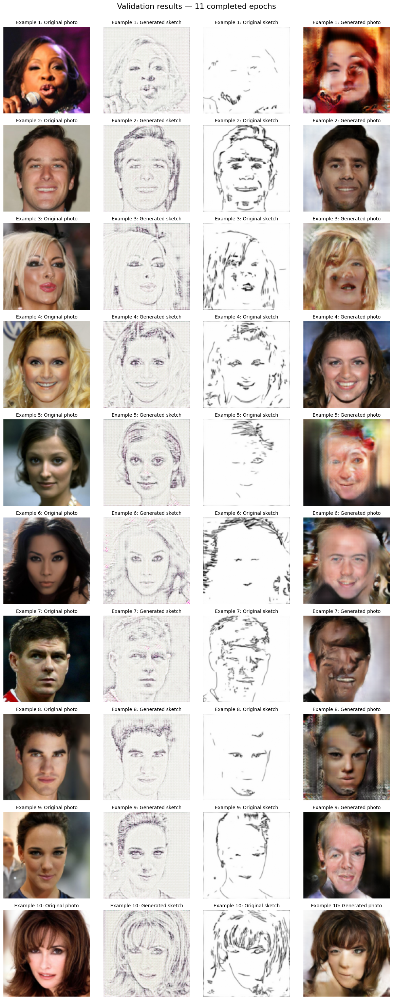

Saved: /kaggle/working/CycleGAN_Assignment/128px_resnet6/samples/validation_10_epoch_011.png


In [35]:
import matplotlib.pyplot as plt

def show_validation_examples(count=10):
    """Display photo-to-sketch and sketch-to-photo validation results."""
    examples = tf.data.Dataset.zip(
        (val_photos.unbatch(), val_sketches.unbatch())
    ).take(count)

    rows = list(examples)
    if not rows:
        print("No validation images found.")
        return

    fig, axes = plt.subplots(
        len(rows), 4,
        figsize=(12, 3 * len(rows)),
        squeeze=False
    )

    titles = [
        "Original photo",
        "Generated sketch",
        "Original sketch",
        "Generated photo"
    ]

    for row, (photo, sketch) in enumerate(rows):
        # Add a batch dimension; inference does not update weights.
        generated_sketch = G(photo[None, ...], training=False)[0]
        generated_photo = F(sketch[None, ...], training=False)[0]

        images = [photo, generated_sketch, sketch, generated_photo]

        for col, image in enumerate(images):
            display_image = tf.clip_by_value((image + 1) / 2, 0, 1)

            axes[row, col].imshow(display_image)
            axes[row, col].set_title(
                f"Example {row + 1}: {titles[col]}", fontsize=10
            )
            axes[row, col].axis("off")

    epoch = int(completed_epochs.numpy())
    fig.suptitle(
        f"Validation results — {epoch} completed epochs",
        fontsize=16
    )
    plt.tight_layout(rect=[0, 0, 1, 0.98])

    output_path = SAMPLE_DIR / f"validation_{len(rows)}_epoch_{epoch:03d}.png"
    fig.savefig(output_path, dpi=150, bbox_inches="tight")

    plt.show()
    plt.close(fig)

    print("Saved:", output_path)


show_validation_examples(count=10)

In [36]:
print("Completed epochs:", int(completed_epochs.numpy()))

Completed epochs: 11


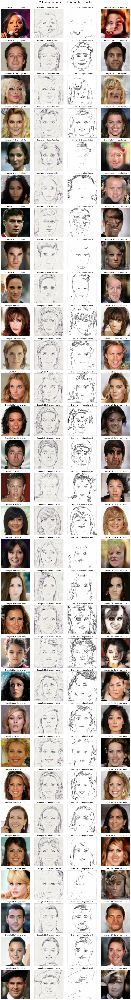

Saved: /kaggle/working/CycleGAN_Assignment/128px_resnet6/samples/validation_30_epoch_011.png


In [42]:
show_validation_examples(count=30)

### TEST INFERENCE

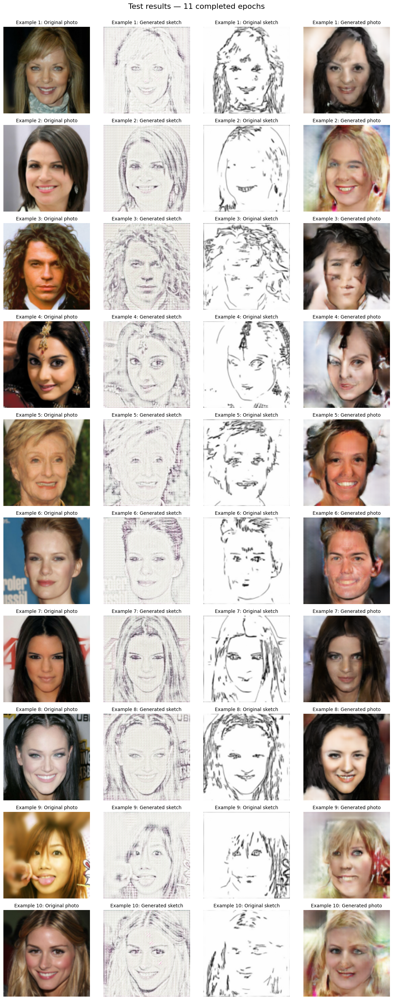

Saved: /kaggle/working/CycleGAN_Assignment/128px_resnet6/samples/test_10_epoch_011.png


In [50]:
import matplotlib.pyplot as plt

def test_model(count=10):
    """Run the trained generators on the TEST split and display the results."""
    examples = tf.data.Dataset.zip(
        (test_photos.unbatch(), test_sketches.unbatch())
    ).take(count)

    rows = list(examples)

    fig, axes = plt.subplots(len(rows), 4, figsize=(12, 3 * len(rows)), squeeze=False)
    titles = ["Original photo", "Generated sketch", "Original sketch", "Generated photo"]

    for row, (photo, sketch) in enumerate(rows):
        generated_sketch = G(photo[None, ...], training=False)[0]
        generated_photo = F(sketch[None, ...], training=False)[0]

        for col, image in enumerate([photo, generated_sketch, sketch, generated_photo]):
            axes[row, col].imshow(tf.clip_by_value((image + 1) / 2, 0, 1))
            axes[row, col].set_title(f"Example {row + 1}: {titles[col]}", fontsize=10)
            axes[row, col].axis("off")

    epoch = int(completed_epochs.numpy())
    fig.suptitle(f"Test results — {epoch} completed epochs", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.98])

    output_path = SAMPLE_DIR / f"test_{len(rows)}_epoch_{epoch:03d}.png"
    fig.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved:", output_path)


test_model(count=10)

### Training Losses

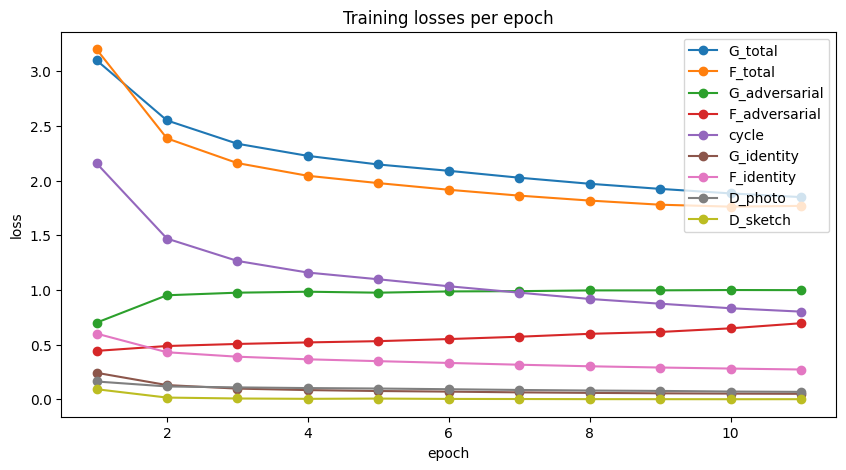

In [45]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(RUN_DIR / "training_history.csv")
cols = [c for c in df.columns if c not in ("epoch", "minutes")]
df.plot(x="epoch", y=cols, figsize=(10, 5), marker="o")
plt.ylabel("loss"); plt.title("Training losses per epoch")
plt.savefig(RUN_DIR / "loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()

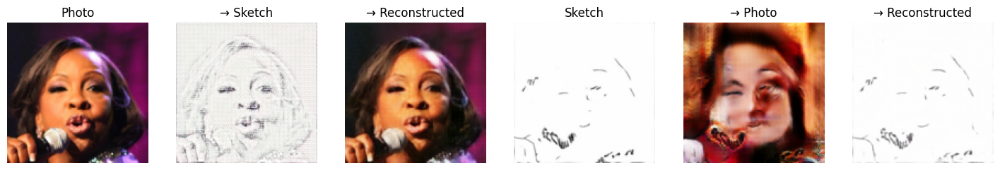

In [46]:
photo = fixed_photo; sketch = fixed_sketch
fake_sketch = G(photo, training=False); rec_photo = F(fake_sketch, training=False)
fake_photo = F(sketch, training=False); rec_sketch = G(fake_photo, training=False)
imgs = [photo, fake_sketch, rec_photo, sketch, fake_photo, rec_sketch]
titles = ["Photo", "→ Sketch", "→ Reconstructed", "Sketch", "→ Photo", "→ Reconstructed"]
fig, ax = plt.subplots(1, 6, figsize=(18, 3.5))
for a, im, t in zip(ax, imgs, titles):
    a.imshow(tf.clip_by_value((im[0] + 1) / 2, 0, 1)); a.set_title(t); a.axis("off")
plt.savefig(RUN_DIR / "cycle_consistency.png", dpi=150, bbox_inches="tight"); plt.show()

### TEST LOSSES

Test losses:   0%|          | 0/679 [00:00<?, ?it/s]

,Test,Last training epoch
G_total,1.8875,1.8488
F_total,2.0020,1.7685
G_adversarial,1.0007,0.9979
F_adversarial,0.8779,0.6952
cycle,0.8378,0.8014
G_identity,0.0490,0.0495
F_identity,0.2864,0.2720
D_photo,0.0806,0.0675
D_sketch,0.0000,0.0004


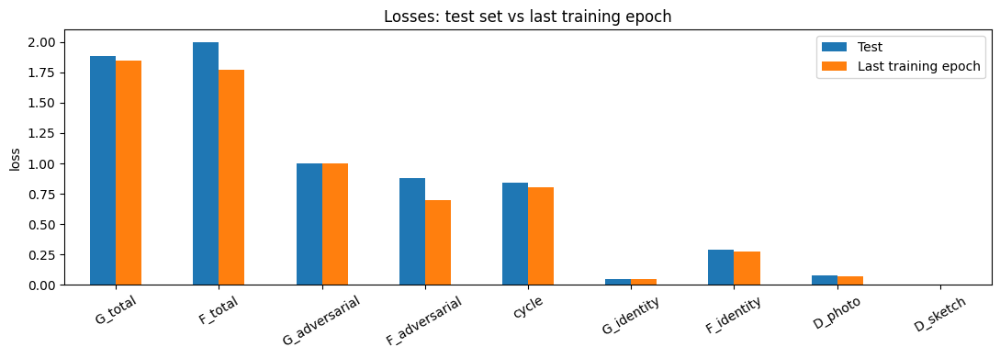

Saved: /kaggle/working/CycleGAN_Assignment/128px_resnet6/test_losses_epoch_011.json


In [51]:
import json
import pandas as pd
from tqdm.auto import tqdm

def test_losses():
    """Compute the training losses on the full TEST split (no weight updates)."""
    names = ["G_total", "F_total", "G_adversarial", "F_adversarial",
             "cycle", "G_identity", "F_identity", "D_photo", "D_sketch"]
    metrics = {n: tf.keras.metrics.Mean() for n in names}

    steps = len(test_photo_paths)
    for real_photo, real_sketch in tqdm(
        tf.data.Dataset.zip((test_photos, test_sketches)), total=steps, desc="Test losses"
    ):
        fake_sketch = G(real_photo, training=False)
        fake_photo = F(real_sketch, training=False)
        cycled_photo = F(fake_sketch, training=False)
        cycled_sketch = G(fake_photo, training=False)
        same_sketch = G(real_sketch, training=False)
        same_photo = F(real_photo, training=False)

        fake_sketch_scores = D_sketch(fake_sketch, training=False)
        fake_photo_scores = D_photo(fake_photo, training=False)

        G_adv = generator_adversarial_loss(fake_sketch_scores)
        F_adv = generator_adversarial_loss(fake_photo_scores)
        cycle = (cycle_consistency_loss(real_photo, cycled_photo)
                 + cycle_consistency_loss(real_sketch, cycled_sketch))
        G_id = identity_loss(real_sketch, same_sketch)
        F_id = identity_loss(real_photo, same_photo)

        d_photo = discriminator_loss(D_photo(real_photo, training=False), fake_photo_scores)
        d_sketch = discriminator_loss(D_sketch(real_sketch, training=False), fake_sketch_scores)

        values = {
            "G_total": G_adv + cycle + G_id, "F_total": F_adv + cycle + F_id,
            "G_adversarial": G_adv, "F_adversarial": F_adv, "cycle": cycle,
            "G_identity": G_id, "F_identity": F_id,
            "D_photo": d_photo, "D_sketch": d_sketch,
        }
        for n, v in values.items():
            metrics[n].update_state(v)

    results = {n: float(m.result().numpy()) for n, m in metrics.items()}

    # Compare against the last training epoch (columns that exist in your CSV)
    table = pd.DataFrame({"Test": results})
    history = pd.read_csv(HISTORY_PATH)
    last = history.iloc[-1]
    table["Last training epoch"] = [float(last[n]) if n in history.columns else float("nan")
                                    for n in table.index]
    table = table.round(4)
    display(table)

    ax = table.plot.bar(figsize=(11, 4), rot=30)
    ax.set_title("Losses: test set vs last training epoch")
    ax.set_ylabel("loss")
    plt.tight_layout()
    plt.savefig(RUN_DIR / "test_losses.png", dpi=150, bbox_inches="tight")
    plt.show()

    epoch = int(completed_epochs.numpy())
    path = RUN_DIR / f"test_losses_epoch_{epoch:03d}.json"
    path.write_text(json.dumps({"split": "test", "count": steps, **results}, indent=2))
    print("Saved:", path)
    return results


test_results = test_losses()

### CALCULATING FID USING VALIDATION TEST

In [ ]:
%pip -q install clean-fid

In [37]:
import tempfile
from pathlib import Path

import numpy as np
import tensorflow as tf
from PIL import Image
from tqdm.auto import tqdm

EVAL_SPLIT = "val"  # "val" for development; "test" for final evaluation.
assert EVAL_SPLIT in {"val", "test"}

photo_paths = get_image_paths(dataset_path / EVAL_SPLIT / "photos")
sketch_paths = get_image_paths(dataset_path / EVAL_SPLIT / "sketches")

# A fresh local folder prevents stale outputs from previous runs being included.
FID_DIR = Path(tempfile.mkdtemp(prefix=f"cyclegan_fid_{EVAL_SPLIT}_"))

folders = {
    name: FID_DIR / name
    for name in [
        "real_photos", "generated_photos",
        "real_sketches", "generated_sketches"
    ]
}

for folder in folders.values():
    folder.mkdir(parents=True, exist_ok=True)


def save_fid_image(image, output_path):
    """Convert [-1, 1] RGB pixels to uint8 and save lossless PNG."""
    tf.debugging.assert_all_finite(image, "Invalid evaluation image")

    pixels = tf.clip_by_value((image + 1.0) * 127.5, 0, 255)
    pixels = tf.cast(tf.round(pixels), tf.uint8).numpy()

    Image.fromarray(pixels).save(output_path)


def export_fid_images(paths, generator, real_folder, generated_folder):
    """Export real inputs and translated outputs without training."""
    for index, path in enumerate(tqdm(paths, desc=generated_folder.name)):
        real_image = load_image(path)  # Existing resize + normalization.
        generated_image = generator(
            real_image[None, ...], training=False
        )[0]

        filename = f"{index:06d}.png"
        save_fid_image(real_image, real_folder / filename)
        save_fid_image(generated_image, generated_folder / filename)


# Real photos provide both photo-domain references and inputs to G.
export_fid_images(
    photo_paths,
    G,
    folders["real_photos"],
    folders["generated_sketches"]
)

# Real sketches provide both sketch-domain references and inputs to F.
export_fid_images(
    sketch_paths,
    F,
    folders["real_sketches"],
    folders["generated_photos"]
)

print("\nEvaluation split:", EVAL_SPLIT)
print("Photos:", len(photo_paths))
print("Sketches:", len(sketch_paths))
print("Image resolution:", IMAGE_SIZE)
print("Temporary image folder:", FID_DIR)

generated_sketches:   0%|          | 0/1000 [00:00<?, ?it/s]

generated_photos:   0%|          | 0/1000 [00:00<?, ?it/s]


Evaluation split: val
Photos: 1000
Sketches: 1000
Image resolution: 128
Temporary image folder: /tmp/cyclegan_fid_val_54uoqo2g


In [43]:
import torch
from cleanfid import fid

FID_DEVICE = torch.device("cpu")


def calculate_fid(real_folder, generated_folder):
    """Calculate Clean-FID using Inception features for two image folders."""
    return float(
        fid.compute_fid(
            str(real_folder),
            str(generated_folder),
            mode="clean",
            model_name="inception_v3",
            device=FID_DEVICE,
            batch_size=16,
            num_workers=0,
            use_dataparallel=False   # NEW: fixes the cuda:0 vs cpu error on 2-GPU sessions
        )
    )


fid_photo_to_sketch = calculate_fid(
    folders["real_sketches"],
    folders["generated_sketches"]
)

fid_sketch_to_photo = calculate_fid(
    folders["real_photos"],
    folders["generated_photos"]
)

print("\n========== FID RESULTS ==========")
print(f"Photo → Sketch FID: {fid_photo_to_sketch:.4f}")
print(f"Sketch → Photo FID: {fid_sketch_to_photo:.4f}")
print("Lower is better. These are NOT accuracy percentages.")

compute FID between two folders
Found 1000 images in the folder /tmp/cyclegan_fid_val_54uoqo2g/real_sketches


FID real_sketches : 100%|██████████| 63/63 [02:13<00:00,  2.12s/it]


Found 1000 images in the folder /tmp/cyclegan_fid_val_54uoqo2g/generated_sketches


FID generated_sketches : 100%|██████████| 63/63 [02:13<00:00,  2.12s/it]


compute FID between two folders
Found 1000 images in the folder /tmp/cyclegan_fid_val_54uoqo2g/real_photos


FID real_photos : 100%|██████████| 63/63 [02:15<00:00,  2.14s/it]


Found 1000 images in the folder /tmp/cyclegan_fid_val_54uoqo2g/generated_photos


FID generated_photos : 100%|██████████| 63/63 [02:15<00:00,  2.15s/it]



========== FID RESULTS ==========
Photo → Sketch FID: 135.8434
Sketch → Photo FID: 68.5298
Lower is better. These are NOT accuracy percentages.


In [44]:
import json
from datetime import datetime, timezone
from importlib.metadata import version

results = {
    "evaluated_at_utc": datetime.now(timezone.utc).isoformat(),
    "completed_epochs": int(completed_epochs.numpy()),
    "split": EVAL_SPLIT,
    "image_size": IMAGE_SIZE,
    "implementation": "clean-fid",
    "implementation_version": version("clean-fid"),
    "mode": "clean",
    "feature_model": "inception_v3",
    "photo_to_sketch": {
        "fid": fid_photo_to_sketch,
        "real_count": len(sketch_paths),
        "generated_count": len(photo_paths)
    },
    "sketch_to_photo": {
        "fid": fid_sketch_to_photo,
        "real_count": len(photo_paths),
        "generated_count": len(sketch_paths)
    }
}

RUN_DIR.mkdir(parents=True, exist_ok=True)
timestamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
result_path = RUN_DIR / (
    f"fid_{EVAL_SPLIT}_epoch_{int(completed_epochs.numpy()):03d}_{timestamp}.json"
)

result_path.write_text(json.dumps(results, indent=2))
print("Saved results:", result_path)

Saved results: /kaggle/working/CycleGAN_Assignment/128px_resnet6/fid_val_epoch_011_20261016_132016.json


### Calculating FID using test set

In [47]:
import tempfile
from pathlib import Path

import numpy as np
import tensorflow as tf
from PIL import Image
from tqdm.auto import tqdm

EVAL_SPLIT = "test"  # "val" for development; "test" for final evaluation.
assert EVAL_SPLIT in {"val", "test"}

photo_paths = get_image_paths(dataset_path / EVAL_SPLIT / "photos")
sketch_paths = get_image_paths(dataset_path / EVAL_SPLIT / "sketches")

# A fresh local folder prevents stale outputs from previous runs being included.
FID_DIR = Path(tempfile.mkdtemp(prefix=f"cyclegan_fid_{EVAL_SPLIT}_"))

folders = {
    name: FID_DIR / name
    for name in [
        "real_photos", "generated_photos",
        "real_sketches", "generated_sketches"
    ]
}

for folder in folders.values():
    folder.mkdir(parents=True, exist_ok=True)


def save_fid_image(image, output_path):
    """Convert [-1, 1] RGB pixels to uint8 and save lossless PNG."""
    tf.debugging.assert_all_finite(image, "Invalid evaluation image")

    pixels = tf.clip_by_value((image + 1.0) * 127.5, 0, 255)
    pixels = tf.cast(tf.round(pixels), tf.uint8).numpy()

    Image.fromarray(pixels).save(output_path)


def export_fid_images(paths, generator, real_folder, generated_folder):
    """Export real inputs and translated outputs without training."""
    for index, path in enumerate(tqdm(paths, desc=generated_folder.name)):
        real_image = load_image(path)  # Existing resize + normalization.
        generated_image = generator(
            real_image[None, ...], training=False
        )[0]

        filename = f"{index:06d}.png"
        save_fid_image(real_image, real_folder / filename)
        save_fid_image(generated_image, generated_folder / filename)


# Real photos provide both photo-domain references and inputs to G.
export_fid_images(
    photo_paths,
    G,
    folders["real_photos"],
    folders["generated_sketches"]
)

# Real sketches provide both sketch-domain references and inputs to F.
export_fid_images(
    sketch_paths,
    F,
    folders["real_sketches"],
    folders["generated_photos"]
)

print("\nEvaluation split:", EVAL_SPLIT)
print("Photos:", len(photo_paths))
print("Sketches:", len(sketch_paths))
print("Image resolution:", IMAGE_SIZE)
print("Temporary image folder:", FID_DIR)

generated_sketches:   0%|          | 0/679 [00:00<?, ?it/s]

generated_photos:   0%|          | 0/679 [00:00<?, ?it/s]


Evaluation split: test
Photos: 679
Sketches: 679
Image resolution: 128
Temporary image folder: /tmp/cyclegan_fid_test_4e6hk5vt


In [48]:
import torch
from cleanfid import fid

FID_DEVICE = torch.device("cpu")


def calculate_fid(real_folder, generated_folder):
    """Calculate Clean-FID using Inception features for two image folders."""
    return float(
        fid.compute_fid(
            str(real_folder),
            str(generated_folder),
            mode="clean",
            model_name="inception_v3",
            device=FID_DEVICE,
            batch_size=16,
            num_workers=0,
            use_dataparallel=False   # NEW: fixes the cuda:0 vs cpu error on 2-GPU sessions
        )
    )


fid_photo_to_sketch = calculate_fid(
    folders["real_sketches"],
    folders["generated_sketches"]
)

fid_sketch_to_photo = calculate_fid(
    folders["real_photos"],
    folders["generated_photos"]
)

print("\n========== FID RESULTS ==========")
print(f"Photo → Sketch FID: {fid_photo_to_sketch:.4f}")
print(f"Sketch → Photo FID: {fid_sketch_to_photo:.4f}")
print("Lower is better. These are NOT accuracy percentages.")

compute FID between two folders
Found 679 images in the folder /tmp/cyclegan_fid_test_4e6hk5vt/real_sketches


FID real_sketches : 100%|██████████| 43/43 [01:30<00:00,  2.10s/it]


Found 679 images in the folder /tmp/cyclegan_fid_test_4e6hk5vt/generated_sketches


FID generated_sketches : 100%|██████████| 43/43 [01:31<00:00,  2.13s/it]


compute FID between two folders
Found 679 images in the folder /tmp/cyclegan_fid_test_4e6hk5vt/real_photos


FID real_photos : 100%|██████████| 43/43 [01:32<00:00,  2.15s/it]


Found 679 images in the folder /tmp/cyclegan_fid_test_4e6hk5vt/generated_photos


FID generated_photos : 100%|██████████| 43/43 [01:31<00:00,  2.13s/it]



========== FID RESULTS ==========
Photo → Sketch FID: 142.1067
Sketch → Photo FID: 76.5412
Lower is better. These are NOT accuracy percentages.


In [49]:
import json
from datetime import datetime, timezone
from importlib.metadata import version

results = {
    "evaluated_at_utc": datetime.now(timezone.utc).isoformat(),
    "completed_epochs": int(completed_epochs.numpy()),
    "split": EVAL_SPLIT,
    "image_size": IMAGE_SIZE,
    "implementation": "clean-fid",
    "implementation_version": version("clean-fid"),
    "mode": "clean",
    "feature_model": "inception_v3",
    "photo_to_sketch": {
        "fid": fid_photo_to_sketch,
        "real_count": len(sketch_paths),
        "generated_count": len(photo_paths)
    },
    "sketch_to_photo": {
        "fid": fid_sketch_to_photo,
        "real_count": len(photo_paths),
        "generated_count": len(sketch_paths)
    }
}

RUN_DIR.mkdir(parents=True, exist_ok=True)
timestamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
result_path = RUN_DIR / (
    f"fid_{EVAL_SPLIT}_epoch_{int(completed_epochs.numpy()):03d}_{timestamp}.json"
)

result_path.write_text(json.dumps(results, indent=2))
print("Saved results:", result_path)

Saved results: /kaggle/working/CycleGAN_Assignment/128px_resnet6/fid_test_epoch_011_20261016_133614.json


In [52]:
import zipfile
from pathlib import Path

OUT = Path("/kaggle/working")
EXPORT = RUN_DIR / "export"
EXPORT.mkdir(exist_ok=True)

# --- 1) Save the generators ---
G.save(EXPORT / "G_photo2sketch.keras")
F.save(EXPORT / "F_sketch2photo.keras")
G.save_weights(EXPORT / "G_photo2sketch.weights.h5")
F.save_weights(EXPORT / "F_sketch2photo.weights.h5")


def make_zip(zip_path, root, files):
    """Zip the given files, keeping paths relative to `root`."""
    zip_path = Path(zip_path)
    zip_path.unlink(missing_ok=True)
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for f in files:
            z.write(f, f.relative_to(root))
    print(f"{zip_path.name}: {len(files)} files, {zip_path.stat().st_size / 1e6:.0f} MB")


# --- 2) models_and_weights.zip: only what the Flask app needs ---
model_files = sorted(EXPORT.glob("*"))
make_zip(OUT / "models_and_weights.zip", EXPORT, model_files)

# --- 3) CycleGAN_checkpoints_and_samples.zip: everything for the report / resuming training ---
# Keeps the CycleGAN_Assignment/128px_resnet6/... folder layout, so uploading it
# as a Kaggle dataset works with your existing checkpoint-copy cell.
ONLY_LATEST_CKPT = False   # True = keep just the newest checkpoint (about 1/3 the size)

root = RUN_DIR.parent.parent          # /kaggle/working
run_files = [p for p in RUN_DIR.rglob("*") if p.is_file() and EXPORT not in p.parents]

if ONLY_LATEST_CKPT:
    latest = checkpoint_manager.latest_checkpoint            # ".../ckpt-254"
    run_files = [
        p for p in run_files
        if p.parent != CHECKPOINT_DIR
        or p.name == "checkpoint"
        or p.name.startswith(Path(latest).name + ".")
    ]

make_zip(OUT / "CycleGAN_checkpoints_and_samples.zip", root, sorted(run_files))

# --- 4) Summary of what went into each zip ---
print("\nmodels_and_weights.zip:")
for p in model_files:
    print("  ", p.name)

print("\nCycleGAN_checkpoints_and_samples.zip contains:")
for sub in ["checkpoints", "samples"]:
    n = sum(1 for p in run_files if sub in p.parts)
    print(f"   {sub}/  ({n} files)")
for p in sorted(p for p in run_files if p.parent == RUN_DIR):
    print("  ", p.name)

models_and_weights.zip: 4 files, 117 MB
CycleGAN_checkpoints_and_samples.zip: 35 files, 758 MB

models_and_weights.zip:
   F_sketch2photo.keras
   F_sketch2photo.weights.h5
   G_photo2sketch.keras
   G_photo2sketch.weights.h5

CycleGAN_checkpoints_and_samples.zip contains:
   checkpoints/  (7 files)
   samples/  (20 files)
   cycle_consistency.png
   fid_test_epoch_011_20261016_133614.json
   fid_val_epoch_005_20261015_191729.json
   fid_val_epoch_011_20261016_132016.json
   loss_curves.png
   test_losses.png
   test_losses_epoch_011.json
   training_history.csv
